<div style="
    background: linear-gradient(90deg, #6A5ACD, #20B2AA);
    padding: 25px 10px;
    border-radius: 12px;
    text-align: center;
    margin: 10px 0;
">
    <h1 style="
        color: white;
        font-size: 30px;
        font-family: Arial, sans-serif;
        font-weight: bold;
        margin: 0;
    ">
        E-Commerce Customer Behavior and Purchase Intention Analysis
    </h1>
</div>

### Introduction to E-Commerce Customer Behavior and Purchase Intention Analysis

E-commerce refers to buying and selling products or services through online platforms. Understanding online shopper behaviour helps businesses identify browsing patterns and factors that may influence customers to make a purchase.

The purpose of this analysis is to understand online shopper behaviour and identify key factors associated with purchase intention through clear and meaningful data visualization. This project uses Python libraries such as **Pandas, NumPy, Plotly, Matplotlib, and Seaborn** to analyse the online shoppers purchasing intention dataset.


### Data Source

The dataset used for this project is the **Online Shoppers Purchasing Intention Dataset**, obtained from the UCI Machine Learning Repository.

The dataset contains information about online shopping sessions, including page visits, browsing duration, visitor type, traffic source, and whether a purchase was made during the session.

**Dataset Link:** [Online Shoppers Purchasing Intention Dataset](https://archive.ics.uci.edu/dataset/468/online+shoppers+purchasing+intention)

### Attribute Details

The dataset contains 18 attributes describing visitors' browsing behaviour, session characteristics, and purchase outcomes. Each attribute provides information that helps analyse online shopping patterns and understand factors associated with purchase intention.


| No. | Attribute | Description |
|:---:|---|---|
| 1 | Administrative | Number of administrative pages visited during the session. |
| 2 | Administrative_Duration | Time spent on administrative pages. |
| 3 | Informational | Number of informational pages visited during the session. |
| 4 | Informational_Duration | Time spent on informational pages. |
| 5 | ProductRelated | Number of product-related pages visited during the session. |
| 6 | ProductRelated_Duration | Time spent on product-related pages. |
| 7 | BounceRates | Average bounce rate of the pages visited during the session. |
| 8 | ExitRates | Average exit rate of the pages visited during the session. |
| 9 | PageValues | Average value of pages visited before completing a transaction. |
| 10 | SpecialDay | Closeness of the visit date to a special day or occasion. |
| 11 | OperatingSystems | Operating system used by the visitor. |
| 12 | Browser | Browser used by the visitor. |
| 13 | Region | Geographic region of the visitor. |
| 14 | TrafficType | Category of traffic source that brought the visitor to the website. |
| 15 | VisitorType | Type of visitor, such as returning visitor or new visitor. |
| 16 | Month | Month in which the session occurred. |
| 17 | Weekend | Indicates whether the session occurred on a weekend. |
| 18 | Revenue | Indicates whether a purchase was completed during the session (True or False). |

The following Python libraries are used for data manipulation, numerical operations, data visualization, and interactive charts.

* **Pandas:** Data manipulation and analysis.
* **NumPy:** Numerical operations.
* **Matplotlib:** Creating charts and plots.
* **Seaborn:** Creating statistical visualizations.
* **Plotly Express:** Creating interactive visualizations.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

## Data Loading and Initial Overview


In this section, the dataset is loaded into a Pandas DataFrame. The initial overview helps us understand the structure, size, column names, and data types of the dataset before performing data preprocessing and analysis.

### (1) Dataset Loading

In [2]:
df=pd.read_csv("online_shoppers_intention.csv")

***info:*** The dataset is imported into a Pandas DataFrame using the `read_csv()` function. This allows us to access, inspect, and analyse the data using Python.

### (2) Initial Overview of the Dataset

In [3]:
#Viewing the Dataset
df.head()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


***info:*** The `head()` method is used to display the first five rows of the dataset. This provides an initial look at the data and helps us understand how the values are organised across different columns.

In [4]:
# Display Dataset Dimensions
df.shape 

(12330, 18)

***info:*** The `shape` attribute is used to determine the total number of rows and columns in the dataset. This helps us understand the size of the dataset before proceeding with data preprocessing.

In [5]:
##Checking DataFrame Structural Summary
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  str    
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14  TrafficType              12330 no

***Info:*** Provides a complete summary of the dataset.It displays the number of rows and columns,column names,non-null value counts,and data type of each column,as well as the memory usage of the DataFrame.Therefore it helps to identify which columns need preprocessing.

In [6]:
#Display Column Names
df.columns

Index(['Administrative', 'Administrative_Duration', 'Informational',
       'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration',
       'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay', 'Month',
       'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'VisitorType',
       'Weekend', 'Revenue'],
      dtype='str')

***info:*** The `columns` attribute is used to display all the column names in the dataset. This helps us identify the available attributes and refer to them correctly during data analysis and preprocessing.

In [7]:
#Checking Missing Values
df.isnull().sum()

Administrative             0
Administrative_Duration    0
Informational              0
Informational_Duration     0
ProductRelated             0
ProductRelated_Duration    0
BounceRates                0
ExitRates                  0
PageValues                 0
SpecialDay                 0
Month                      0
OperatingSystems           0
Browser                    0
Region                     0
TrafficType                0
VisitorType                0
Weekend                    0
Revenue                    0
dtype: int64

***info:*** Used to find how many missing values are present in each column.

In [8]:
#Displaying Statistical Summary
df.describe()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,OperatingSystems,Browser,Region,TrafficType
count,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000
mean,2.315166,80.818611,0.503569,34.472398,31.731468,1194.746220,0.022191,0.043073,5.889258,0.061427,2.124006,2.357097,3.147364,4.069586
std,3.321784,176.779107,1.270156,140.749294,44.475503,1913.669288,0.048488,0.048597,18.568437,0.198917,0.911325,1.717277,2.401591,4.025169
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,1.000000
25%,0.000000,0.000000,0.000000,0.000000,7.000000,184.137500,0.000000,0.014286,0.000000,0.000000,2.000000,2.000000,1.000000,2.000000
50%,1.000000,7.500000,0.000000,0.000000,18.000000,598.936905,0.003112,0.025156,0.000000,0.000000,2.000000,2.000000,3.000000,2.000000
75%,4.000000,93.256250,0.000000,0.000000,38.000000,1464.157214,0.016813,0.050000,0.000000,0.000000,3.000000,2.000000,4.000000,4.000000
max,27.000000,3398.750000,24.000000,2549.375000,705.000000,63973.522230,0.200000,0.200000,361.763742,1.000000,8.000000,13.000000,9.000000,20.000000


***Info:*** Provides summary statistics for numerical columns including mean,median,standard deviation,minimum and maximum values.

In [9]:
#Checking Duplicate Records
print("Duplicate records found:",df.duplicated().sum())

Duplicate records found: 125


***info:*** The `duplicated()` method identifies duplicate rows, and the `sum()` function counts the total number of duplicate records in the dataset.
The duplicate record check identified 125 duplicate rows in the dataset.

## Data Pre-processing 


This step ensures the dataset is clean,consistent,and suitable for analysis.The cleaning steps include (1)**Handling missing values**,(2)**Removing duplicates**,(3)**Correcting Data Types**(4)**Creating Derived columns**,(5)**Filtering data**(6)**Standardizing column names and Categorical values**.

#### (1) Handling missing values

**Observation:**  The missing value check shows that all 18 columns contain zero missing values. Therefore, no missing value treatment is required for the dataset.

#### (2) Removing duplicates

In [10]:
#Removing duplicates
df.drop_duplicates(inplace=True)

In [11]:
#Verifying the removal of duplicates
print("Duplicate records found after removal:",df.duplicated().sum())

Duplicate records found after removal: 0


In [12]:
#checking the dimensions of the dataset after removing duplicates
print("Dimensions of the dataset after removing duplicates:", df.shape)

Dimensions of the dataset after removing duplicates: (12205, 18)


***info:*** The dataset was checked for duplicate entries using `df.duplicated().sum()` during the initial overview, which identified 125 duplicate rows. The `drop_duplicates()` function was applied to remove these records. After removal, the dataset was verified to ensure that no duplicate rows remained. Now the dataset contains 12,205 rows and 18 columns.

#### (3) Correcting Data Types

In [13]:
#checking the data types of each column
df.dtypes

Administrative               int64
Administrative_Duration    float64
Informational                int64
Informational_Duration     float64
ProductRelated               int64
ProductRelated_Duration    float64
BounceRates                float64
ExitRates                  float64
PageValues                 float64
SpecialDay                 float64
Month                          str
OperatingSystems             int64
Browser                      int64
Region                       int64
TrafficType                  int64
VisitorType                    str
Weekend                       bool
Revenue                       bool
dtype: object

***info:*** The data types of the dataset were examined. The numerical columns use integer or floating-point types, while `Month` and `VisitorType` contain strings, and `Weekend` and `Revenue` contain Boolean values. All existing data types are suitable for the intended analysis; therefore, no data type conversion was necessary.

#### (4) Creating Derived Columns

In this step, three new columns, `TotalPagesVisited`, `BrowsingActivityCategory`, and `TotalPageDuration`, are created using existing attributes. The `TotalPagesVisited` column represents the total number of administrative, informational, and product-related pages visited during a session. The `BrowsingActivityCategory` column classifies sessions into Low, Medium, and High browsing activity based on the total number of pages visited. The `TotalPageDuration` column represents the combined time spent on administrative, informational, and product-related pages. These derived columns help us understand visitors' browsing behaviour and support further analysis of purchase patterns.

In [14]:
#Creating a new column "TotalPagesVisited" that sums up the values of "Administrative", "Informational", and "ProductRelated" columns
df["TotalPagesVisited"] = (df["Administrative"] + df["Informational"] + df["ProductRelated"])

In [15]:
# Viewing the first few rows of the selected columns
df[["Administrative", "Informational", "ProductRelated", "TotalPagesVisited"]].head(8)

,Administrative,Informational,ProductRelated,TotalPagesVisited
0,0,0,1,1
1,0,0,2,2
2,0,0,1,1
3,0,0,2,2
4,0,0,10,10
5,0,0,19,19
6,0,0,1,1
7,1,0,0,1


***info:*** A new column, `TotalPagesVisited`, was created by adding the values of `Administrative`, `Informational`, and `ProductRelated`. This derived column represents the total number of pages visited during each session and can be used to analyse visitors' browsing activity.

In [16]:
#Before creating new column "BrowsingActivityCategory" based on the values of "TotalPagesVisited" column, checking the
#  statistical summary of "TotalPagesVisited" column to understand its distribution and determine appropriate thresholds for categorization.
df["TotalPagesVisited"].describe()

count    12205.000000
mean        34.893240
std         46.627336
min          0.000000
25%          9.000000
50%         20.000000
75%         42.000000
max        746.000000
Name: TotalPagesVisited, dtype: float64

In [17]:
#creating a new column "BrowsingActivityCategory" based on the values of "TotalPagesVisited" column
df["BrowsingActivity"] = pd.cut(df["TotalPagesVisited"], bins=[-1, 9, 42, float("inf")], labels=["Low", "Medium", "High"])

In [18]:
#Count the sessions in each category
df["BrowsingActivity"].value_counts()

BrowsingActivity
Medium    5909
Low       3290
High      3006
Name: count, dtype: int64

***info:*** The statistical summary of `TotalPagesVisited` was examined to understand the distribution of page visits.

The sessions were classified into three categories: **Low** (9 or fewer pages), **Medium** (more than 9 and up to 42 pages), and **High** (more than 42 pages). Finally, the `value_counts()`methods were used to count the sessions in each category and display the results in category order.

In [19]:
#Creating a new column "TotalPageDuration" that sums up the values of "Administrative_Duration", "Informational_Duration", and "ProductRelated_Duration" columns
df["TotalPageDuration"] = (df["Administrative_Duration"] + df["Informational_Duration"] + df["ProductRelated_Duration"])

In [20]:
#Viewing the first few rows of the selected columns
df[["Administrative_Duration", "Informational_Duration", "ProductRelated_Duration", "TotalPageDuration"]].head()

,Administrative_Duration,Informational_Duration,ProductRelated_Duration,TotalPageDuration
0,0.0,0.0,0.000000,0.000000
1,0.0,0.0,64.000000,64.000000
2,0.0,0.0,0.000000,0.000000
3,0.0,0.0,2.666667,2.666667
4,0.0,0.0,627.500000,627.500000


**Info:** A new column, `TotalPageDuration`, was created by adding the values of `Administrative_Duration`, `Informational_Duration`, and `ProductRelated_Duration` for each session. This column represents the combined time spent on these three types of pages and helps us understand visitors' browsing duration. It can also be used in further analysis to explore the relationship between browsing duration and purchase behaviour.

#### (5) Filtering Data

Filtering is the process of selecting specific rows from a dataset based on given conditions. In this step, we examine the dataset to determine whether any records need to be filtered for further analysis. Data will only be removed when there is a clear reason to do so, ensuring that useful information is preserved.


 Since all records are relevant to analysing customer browsing behaviour and purchase intention, no additional filtering was required at this stage.

#### (6) Standardizing Column Names and Categorical Values


### Standardizing Column Names:

In this step, leading and trailing spaces are removed, all column names are converted to lowercase, and underscores are added to separate words in selected column names. This creates a consistent naming convention and makes column names easier to read and use in Python.

In [21]:
#Displaying All Column Names
print("Original Column Names:",df.columns.tolist())

Original Column Names: ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay', 'Month', 'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'VisitorType', 'Weekend', 'Revenue', 'TotalPagesVisited', 'BrowsingActivity', 'TotalPageDuration']


In [22]:
# Standardizing Column Names

df.columns = df.columns.str.strip().str.lower()

df.rename(columns={
    "productrelated": "product_related",
    "visitortype": "visitor_type",
    "operatingsystems": "operating_systems",
    "traffictype": "traffic_type",
    "totalpagesvisited": "total_pages_visited",
    "browsingactivity": "browsing_activity",
    "totalpageduration": "total_page_duration",
    "productrelated_duration": "product_related_duration",
    "bouncerates": "bounce_rates"
}, inplace=True)

In [23]:
#Displaying Updated Column Names
print("Updated Column Names:",df.columns.tolist())

Updated Column Names: ['administrative', 'administrative_duration', 'informational', 'informational_duration', 'product_related', 'product_related_duration', 'bounce_rates', 'exitrates', 'pagevalues', 'specialday', 'month', 'operating_systems', 'browser', 'region', 'traffic_type', 'visitor_type', 'weekend', 'revenue', 'total_pages_visited', 'browsing_activity', 'total_page_duration']


***Info:***  **`str.strip()`** removes leading and trailing spaces from column names to avoid hidden formatting issues. **`str.lower()`** converts all column names to lowercase to maintain a consistent naming convention. **`rename()`** is used to add underscores between words in selected column names, improving readability and making them easier to use during data analysis.

### Standardizing Categorical Values:

Categorical values represent groups or categories within a dataset. In this step, we examine the unique values in categorical columns to identify inconsistent labels or formatting that may need to be standardized.

In [24]:
# Checking Unique Categorical Values

print("Month:", df["month"].unique())
print("Visitor Type:", df["visitor_type"].unique())
print("Weekend:", df["weekend"].unique())
print("Revenue:", df["revenue"].unique())

Month: <StringArray>
['Feb', 'Mar', 'May', 'Oct', 'June', 'Jul', 'Aug', 'Nov', 'Sep', 'Dec']
Length: 10, dtype: str
Visitor Type: <StringArray>
['Returning_Visitor', 'New_Visitor', 'Other']
Length: 3, dtype: str
Weekend: [False  True]
Revenue: [False  True]


In [25]:
# Standardizing Month Values, keeping only the first three letters of the month names for consistency
df["month"] = df["month"].str[:3]

In [26]:
# viewing the unique values of the "month" column after standardization
df["month"].unique()

<StringArray>
['Feb', 'Mar', 'May', 'Oct', 'Jun', 'Jul', 'Aug', 'Nov', 'Sep', 'Dec']
Length: 10, dtype: str

***Info:*** The unique values in the categorical columns were examined to identify inconsistencies.

The `month` column contains a mixture of abbreviated and full month names. Therefore, the month values are standardized to use a consistent three-letter format.

In visitor type column, The categories `Returning_Visitor`, `New_Visitor`, and `Other` follow a consistent naming format. Therefore, no standardization was required for this column.

In the `weekend` and `revenue` columns, Both columns contain consistent Boolean values (`True` and `False`). The `weekend` column indicates whether a session occurred on a weekend, while the `revenue` column indicates whether a purchase was completed. Therefore, no standardization was required for these columns.


<div style="margin-top:15px;background:#e7f9ed;padding:12px 16px;border-left:5px solid #2ecc71;border-radius:6px;font-family:Arial,sans-serif;font-weight:bold;color:#0d6b2d;">
    ✔ Data Preprocessing Successfully Completed!!<br>
    The dataset has been cleaned and prepared for Exploratory Data Analysis (EDA).
</div>

<h2 style="
    text-align:center;
    background-color:#eef3ff;
    padding:10px 15px;
    border-radius:5px;
    color:#2c7be5;
    font-size:30px;
">
    Exploratory Data Analysis (EDA)
</h2>

Exploratory Data Analysis (EDA) is the process of examining and analysing a dataset to understand its characteristics, identify patterns, and discover relationships between variables. In this section, descriptive statistics, data aggregation, and visualizations will be used to explore customer browsing behaviour and identify factors associated with purchase intention.

#### (1) Univariate Analysis

Univariate analysis examines one variable at a time to understand its distribution and characteristics.

#### Numerical Variable Analysis

Numerical variable analysis helps us understand the characteristics of numerical variables using descriptive statistics such as the mean, median, standard deviation, minimum, and maximum. These statistics provide an overview of customer browsing behaviour and session characteristics.

In [27]:
# Numerical Variable Analysis

df.describe()

,administrative,administrative_duration,informational,informational_duration,product_related,product_related_duration,bounce_rates,exitrates,pagevalues,specialday,operating_systems,browser,region,traffic_type,total_pages_visited,total_page_duration
count,12205.000000,12205.000000,12205.000000,12205.000000,12205.000000,12205.000000,12205.000000,12205.000000,12205.000000,12205.000000,12205.000000,12205.000000,12205.000000,12205.000000,12205.000000,12205.000000
mean,2.338878,81.646331,0.508726,34.825454,32.045637,1206.982457,0.020370,0.041466,5.949574,0.061942,2.124211,2.357804,3.153298,4.073904,34.893240,1323.454242
std,3.330436,177.491845,1.275617,141.424807,44.593649,1919.601400,0.045255,0.046163,18.653671,0.199666,0.906823,1.710114,2.402340,4.016654,46.627336,2043.871589
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,8.000000,193.000000,0.000000,0.014231,0.000000,0.000000,2.000000,2.000000,1.000000,2.000000,9.000000,231.666667
50%,1.000000,9.000000,0.000000,0.000000,18.000000,608.942857,0.002899,0.025000,0.000000,0.000000,2.000000,2.000000,3.000000,2.000000,20.000000,690.958333
75%,4.000000,94.700000,0.000000,0.000000,38.000000,1477.154762,0.016667,0.048529,0.000000,0.000000,3.000000,2.000000,4.000000,4.000000,42.000000,1643.958333
max,27.000000,3398.750000,24.000000,2549.375000,705.000000,63973.522230,0.200000,0.200000,361.763742,1.000000,8.000000,13.000000,9.000000,20.000000,746.000000,69921.647230


***Info:*** The `describe()` method is used to generate descriptive statistics for numerical columns, including count, mean, standard deviation, minimum, maximum, and quartiles. These statistics help us understand the distribution, central tendency, and variability of the numerical attributes.

**Observations:**

- The dataset contains 12,205 observations for each numerical column, consistent with the earlier check showing no missing values.
- The average number of total pages visited per session (`total_pages_visited`) is approximately 34.89, while the median is 20 pages.
- The average total page duration (`total_page_duration`) is approximately 1,323.45, while the median is approximately 690.96.
- The maximum number of pages visited in a session is 746, and the maximum total page duration is approximately 69,921.65. This shows that some sessions had many more page visits and much longer browsing times than others.
- The average bounce_rates is 0.0204, and the average exitrates is 0.0415. These values help us understand the browsing patterns of visitors.

#### Frequency Distribution of Categorical Columns

It involves examining all **categorical columns** to understand the different categories they contain and how **frequently** each category appears in the dataset.

The dataset contains categorical variables with different data types. Some columns, such as `month` and `visitor_type`, contain text values, while `weekend` and `revenue` contain Boolean values. The columns `operating_systems`, `browser`, `region`, and `traffic_type` contain numerical codes representing categories.

Therefore, we created a list of relevant categorical columns explicitly to ensure that all these variables are included in the frequency analysis, regardless of their data types.

In [28]:
categorical_columns = [
    "revenue",
    "visitor_type",
    "month",
    "weekend",
    "browsing_activity",
    "operating_systems",
    "browser",
    "region",
    "traffic_type"
]

for col in categorical_columns:
    print("\nColumn:", col)
    print(df[col].value_counts())


Column: revenue
revenue
False    10297
True      1908
Name: count, dtype: int64

Column: visitor_type
visitor_type
Returning_Visitor    10431
New_Visitor           1693
Other                   81
Name: count, dtype: int64

Column: month
month
May    3329
Nov    2982
Mar    1860
Dec    1706
Oct     549
Sep     448
Aug     433
Jul     432
Jun     285
Feb     181
Name: count, dtype: int64

Column: weekend
weekend
False    9346
True     2859
Name: count, dtype: int64

Column: browsing_activity
browsing_activity
Medium    5909
Low       3290
High      3006
Name: count, dtype: int64

Column: operating_systems
operating_systems
2    6541
1    2549
3    2530
4     478
8      75
6      19
7       7
5       6
Name: count, dtype: int64

Column: browser
browser
2     7883
1     2427
4      731
5      465
6      174
10     163
8      135
3      105
13      56
7       49
12      10
11       6
9        1
Name: count, dtype: int64

Column: region
region
1    4714
3    2379
4    1171
2    1128
6     8

***Observations:***

- Most sessions did not result in a purchase.
- Returning visitors account for the largest share of sessions.
- May has the highest number of sessions among the recorded months.
- Weekday sessions are more frequent than weekend sessions.
- Medium browsing activity is the most common category.
- Operating system 2, browser 2, region 1, and traffic type 2 are the most frequent codes in their respective columns.

#### (2) Bivariate Analysis

Bivariate analysis examines the relationship between two variables to identify patterns and associations in customer browsing behaviour and purchase intention. 

In this section, we compare numerical and categorical variables with purchase outcomes to understand how browsing activity and visitor characteristics are associated with purchasing behaviour.

##### Numerical Variables vs. Purchase Intention

To understand the relationship between numerical variables and purchase intention, I grouped sessions by `revenue` and calculated the mean, median, and count of selected numerical variables. This helps compare browsing behaviour between purchasing and non-purchasing sessions.

In [29]:
# Relationship Between Page Visits and Purchase Intention
df.groupby("revenue")["total_pages_visited"].agg(["mean", "median", "count"])

,mean,median,count
revenue,,,
False,31.651161,18.0,10297
True,52.389937,32.0,1908


***info:***  grouped sessions by `revenue` and calculated the mean, median, and count of `total_pages_visited` to compare browsing activity between purchasing and non-purchasing sessions.

***Observation:***
- Purchasing sessions had a higher average number of page visits (52.39) than non-purchasing sessions (31.65).
- This suggests that a higher number of page visits is associated with purchase outcomes.

In [30]:
#Relationship Between Page Duration and Purchase Intention
df.groupby("revenue")["total_page_duration"].agg(["mean", "median", "count"])

,mean,median,count
revenue,,,
False,1188.215446,600.750,10297
True,2053.304285,1252.075,1908


***info:*** Grouped sessions by `revenue` and calculated the mean, median, and count of `total_page_duration` to compare browsing duration between purchasing and non-purchasing sessions.

***Observation:***

- Purchasing sessions had a higher mean and median page duration than non-purchasing sessions.
- The number of non-purchasing sessions (10,297) was higher than purchasing sessions (1,908).
- These results suggest that purchasing sessions generally had longer page durations than non-purchasing sessions.

#### Categorical Variables vs. Purchase Intention

To compare purchase behaviour across different categories, I created a reusable function called `Purchase_Stats()`. It calculates the number of purchases, purchase percentage, and total sessions for each category of a selected variable.

In [31]:
# Defining a function to calculate purchase statistics based on a given categorical column
def Purchase_Stats(column):
    result = df.groupby(column, observed=True).agg(
        Purchase_Count=("revenue", "sum"),
        Purchase_Percentage=("revenue", lambda x: round(x.mean() * 100, 2)),
        Total_Sessions=("revenue", "count")
    )
    return result

In [32]:
# Purchase Behaviour by Visitor Type
Purchase_Stats("visitor_type")

,Purchase_Count,Purchase_Percentage,Total_Sessions
visitor_type,,,
New_Visitor,422,24.93,1693
Other,16,19.75,81
Returning_Visitor,1470,14.09,10431


***info:*** applied the `Purchase_Stats()` function to `visitor_type` to compare purchase counts, purchase percentages, and total sessions across visitor categories.

**Observation:**

- New visitors had the highest purchase percentage (24.93%), followed by other visitors (19.75%) and returning visitors (14.09%).
- Returning visitors accounted for the largest number of sessions (10,431), with 1,470 sessions resulting in purchases.
- Although returning visitors contributed the highest number of purchases, new visitors had a higher purchase percentage.

In [33]:
# Purchase Behaviour by Month
Purchase_Stats("month")

,Purchase_Count,Purchase_Percentage,Total_Sessions
month,,,
Aug,76,17.55,433
Dec,216,12.66,1706
Feb,3,1.66,181
Jul,66,15.28,432
Jun,29,10.18,285
Mar,192,10.32,1860
May,365,10.96,3329
Nov,760,25.49,2982
Oct,115,20.95,549


***info:*** applied the `Purchase_Stats()` function to `month` to compare purchase counts, purchase percentages, and total sessions across the months in the dataset.

**Observation:**

- November had the highest purchase percentage (25.49%), followed by October (20.95%) and September (19.20%).
- February had the lowest purchase percentage (1.66%), with only 3 purchases out of 181 sessions.
- May recorded the highest number of sessions (3,329) and 365 purchases, while November recorded the highest number of purchases (760).
- These results indicate that purchase behaviour varied across the months in the dataset.

In [34]:
# Purchase Behaviour on Weekdays vs. Weekends
Purchase_Stats("weekend")

,Purchase_Count,Purchase_Percentage,Total_Sessions
weekend,,,
False,1409,15.08,9346
True,499,17.45,2859


***info:*** applied the `Purchase_Stats()` function to `weekend` to compare purchase counts, purchase percentages, and total sessions between weekday and weekend sessions.

**Observation:**

- Weekend sessions had a higher purchase percentage (17.45%) than weekday sessions (15.08%).
- Weekdays recorded more sessions (9,346) and purchases (1,409) than weekends, which recorded 2,859 sessions and 499 purchases.
- Although weekdays had more purchases overall, weekend sessions had a higher purchase percentage.

In [35]:
# Purchase Behaviour by Browsing Activity
Purchase_Stats("browsing_activity")

,Purchase_Count,Purchase_Percentage,Total_Sessions
browsing_activity,,,
Low,191,5.81,3290
Medium,996,16.86,5909
High,721,23.99,3006


***info:*** applied the `Purchase_Stats()` function to `browsing_activity` to compare purchase counts, purchase percentages, and total sessions across low, medium, and high browsing activity levels.

**Observation:**

- High browsing activity had the highest purchase percentage (23.99%), followed by medium activity (16.86%) and low activity (5.81%).
- Sessions with high browsing activity recorded 721 purchases out of 3,006 sessions, while low browsing activity recorded only 191 purchases out of 3,290 sessions.
- Purchase percentage increased across the low, medium, and high browsing activity categories, suggesting that sessions involving more page visits were associated with a higher likelihood of purchase.

#### (3) Multivariate Analysis

It examines the relationships among three or more variables to identify patterns in customer browsing behaviour and purchase intention.

 In this section, we analyse how multiple factors together are associated with purchasing outcomes.

In [36]:
# Purchase Behaviour by Visitor Type and Browsing Activity

df.groupby(["visitor_type", "browsing_activity"], observed=True).agg(
    purchase_count=("revenue", "sum"),
    purchase_percentage=("revenue", lambda x: round(x.mean() * 100, 2)),
    total_sessions=("revenue", "count"))

purchase_count  purchase_percentage  \
visitor_type      browsing_activity                                        
New_Visitor       Low                            77                16.92   
                  Medium                        290                27.03   
                  High                           55                33.33   
Other             Low                             2                 4.17   
                  Medium                         10                35.71   
                  High                            4                80.00   
Returning_Visitor Low                           112                 4.02   
                  Medium                        696                14.48   
                  High                          662                23.34   

                                     total_sessions  
visitor_type      browsing_activity                  
New_Visitor       Low                           455  
                  Medium                       1073  
                  High                          165  
Other             Low                            48  
                  Medium                         28  
                  High                            5  
Returning_Visitor Low                          2787  
                  Medium                       4808  
                  High                         2836

***info:*** grouped sessions by `visitor_type` and `browsing_activity` to examine how purchase behaviour varies across these two variables together. We calculated the purchase count, purchase percentage, and total sessions for each combination.

**Observation:**

- Purchase percentages increased with browsing activity across all three visitor types.
- Among new visitors, the purchase percentage increased from 16.92% for low browsing activity to 33.33% for high browsing activity.
- Among returning visitors, the purchase percentage increased from 4.02% for low browsing activity to 23.34% for high browsing activity.
- The `Other` visitor category showed an 80.00% purchase percentage for high browsing activity; however, this was based on only five sessions, so the result should be interpreted cautiously.
- Overall, higher browsing activity was associated with higher purchase percentages across visitor types in this dataset.

In [37]:
# Purchase Behaviour by Month and Weekend
df.groupby(["month","weekend"],observed=True).agg(
    purchase_count=("revenue","sum"),
    purchase_percentage=("revenue",lambda x: round(x.mean()*100,2)),
    total_sessions=("revenue","count"))

purchase_count  purchase_percentage  total_sessions
month weekend                                                     
Aug   False                64                18.99             337
      True                 12                12.50              96
Dec   False               177                13.16            1345
      True                 39                10.80             361
Feb   False                 2                 1.31             153
      True                  1                 3.57              28
Jul   False                50                15.24             328
      True                 16                15.38             104
Jun   False                24                10.08             238
      True                  5                10.64              47
Mar   False               127                 9.19            1382
      True                 65                13.60             478
May   False               266                10.17            2615
      True                 99                13.87             714
Nov   False               550                25.10            2191
      True                210                26.55             791
Oct   False                85                20.99             405
      True                 30                20.83             144
Sep   False                64                18.18             352
      True                 22                22.92              96

***info:*** grouped sessions by `month` and `weekend` to compare purchase counts, purchase percentages, and total sessions across months and between weekday and weekend sessions.

**Observation:**

- Purchase percentages varied between weekdays and weekends across the months.
- Weekend sessions had higher purchase percentages than weekday sessions in March, May, November, and September, while weekdays had a higher percentage in August.
- November recorded the highest purchase percentage for both weekdays (25.10%) and weekends (26.55%).
- February had the lowest weekday purchase percentage (1.31%). Its weekend percentage was 3.57%, based on only 28 sessions.

In [38]:
# Correlation Analysis 

correlation_columns = [
    "administrative",
    "informational",
    "product_related",
    "bounce_rates",
    "exitrates",
    "pagevalues",
    "total_pages_visited",
    "total_page_duration"
]

correlation_matrix = df[correlation_columns].corr()

correlation_matrix

,administrative,informational,product_related,bounce_rates,exitrates,pagevalues,total_pages_visited,total_page_duration
administrative,1.000000,0.375256,0.428305,-0.213096,-0.311255,0.097017,0.491317,0.418356
informational,0.375256,1.000000,0.372572,-0.109095,-0.159429,0.047406,0.410483,0.431562
product_related,0.428305,0.372572,1.000000,-0.192884,-0.286082,0.054201,0.997169,0.852243
bounce_rates,-0.213096,-0.109095,-0.192884,1.000000,0.902144,-0.115799,-0.202677,-0.179984
exitrates,-0.311255,-0.159429,-0.286082,0.902144,1.000000,-0.173627,-0.300198,-0.255009
pagevalues,0.097017,0.047406,0.054201,-0.115799,-0.173627,1.000000,0.060064,0.055660
total_pages_visited,0.491317,0.410483,0.997169,-0.202677,-0.300198,0.060064,1.000000,0.856760
total_page_duration,0.418356,0.431562,0.852243,-0.179984,-0.255009,0.055660,0.856760,1.000000


***info:*** Correlation analysis helps us understand the strength and direction of relationships between numerical variables. It helps identify which variables tend to increase or decrease together.

**Observation:**

- `product_related` and `total_pages_visited` showed an extremely strong positive correlation (0.997), which is expected because total page visits include product-related page visits.
- `product_related` and `total_page_duration` showed a strong positive correlation (0.852), indicating that more product-related page visits were associated with a higher total recorded page duration.
- `bounce_rates` and `exitrates` showed a strong positive correlation (0.902), indicating that these two metrics were closely related.
- `administrative` and `total_pages_visited` showed a moderate positive correlation (0.491).
- `exitrates` and `total_pages_visited` showed a negative correlation (-0.300), suggesting that sessions with more page visits tended to have lower exit rates.

<div style="margin-top:15px; background:#e7f9ed; padding:12px 16px; border-left:5px solid #2ecc71; border-radius:6px; font-family:Arial,sans-serif; font-weight:bold; color:#0d6b2d;">
    ✔ EDA was successfully performed to understand the dataset.
</div>

<h2 style="
    text-align:center;
    background-color:#eef3ff;
    padding:10px 15px;
    border-radius:5px;
    color:#2c7be5;
    font-size:30px;
">
    Data Visualization
</h2>

This section presents visualizations analysing customer browsing behaviour and purchase intention across different factors. The charts examine purchase patterns by visitor type, month, and weekend, along with browsing activity, page visits, page duration, bounce rates, exit rates, and page values. These visualizations highlight key patterns and relationships identified during the analysis and support a clear understanding of customer behaviour and purchasing trends.

### Importing Required Libraries
The required Python libraries, including Matplotlib, Seaborn, and Plotly, are used to create visualizations that help analyse customer browsing behaviour and purchase patterns.


In [39]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

#### (i) Purchase Distribution

* **Visualization Type:** Bar Chart (Matplotlib)
* **Purpose:** To analyse the overall distribution of purchasing and non-purchasing sessions in the dataset.
* **Insight:** The chart shows that non-purchasing sessions account for the majority of sessions, while a much smaller proportion result in a purchase.


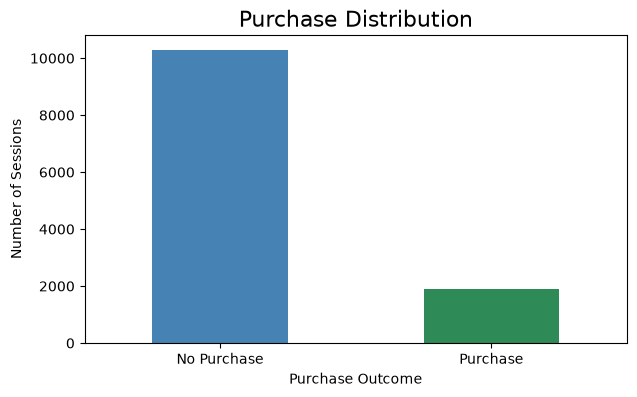

In [40]:
# Create a bar chart
df["revenue"].value_counts().rename({
    False: "No Purchase",
    True: "Purchase"
}).plot(
    kind="bar",
    figsize=(7, 4),
    color=["steelblue", "seagreen"]
)

# Customize the chart
plt.title("Purchase Distribution", fontsize=16)
plt.xlabel("Purchase Outcome")
plt.ylabel("Number of Sessions")
plt.xticks(rotation=0)

plt.show()

### (ii) Purchase Behaviour by Visitor Type

* **Visualization Type:** Grouped Bar Chart (Seaborn)
* **Purpose:** To compare purchasing and non-purchasing sessions across different visitor types.
* **Insight:** Returning visitors account for the highest number of sessions and purchases, followed by new visitors. The number of sessions in the Other category is very low compared with the other visitor types.


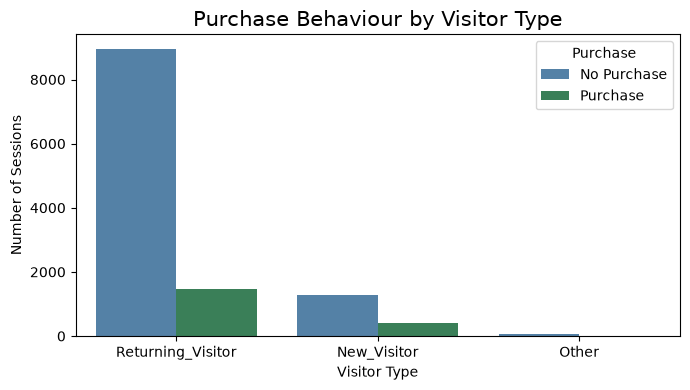

In [41]:
# Create a grouped bar chart
plt.figure(figsize=(7, 4))

sns.countplot(
    data=df,
    x="visitor_type",
    hue="revenue",
    palette={True: "seagreen", False: "steelblue"}
)

# Customize the chart
plt.title("Purchase Behaviour by Visitor Type", fontsize=15)
plt.xlabel("Visitor Type")
plt.ylabel("Number of Sessions")
plt.legend(title="Purchase", labels=["No Purchase", "Purchase"])

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### (iii) Purchase Percentage by Visitor Type

* **Visualization Type:** Bar Chart (Matplotlib)
* **Purpose:** To compare the percentage of sessions resulting in a purchase across different visitor types.
* **Insight:** New visitors have the highest purchase percentage, even though returning visitors account for the highest number of purchases. This helps us compare purchasing behaviour fairly across visitor types with different numbers of sessions.


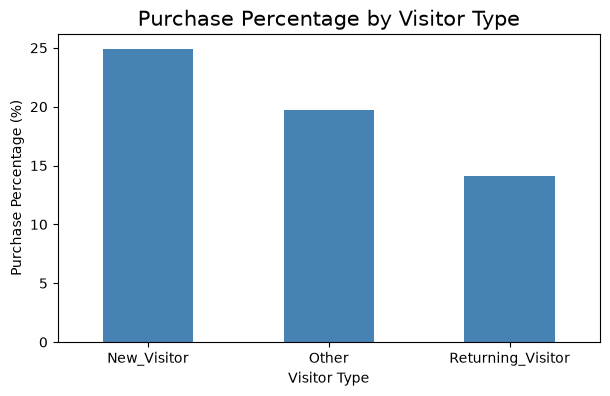

In [42]:
# Calculate purchase percentage for each visitor type
purchase_percentage = df.groupby("visitor_type", observed=True)["revenue"].mean() * 100

# Create a bar chart
purchase_percentage.plot(
    kind="bar",
    figsize=(7, 4),
    color="steelblue"
)

# Customize the chart
plt.title("Purchase Percentage by Visitor Type", fontsize=15)
plt.xlabel("Visitor Type")
plt.ylabel("Purchase Percentage (%)")
plt.xticks(rotation=0)

plt.show()

#### (iv) Purchase Percentage by Month
- ***Visualization Type:*** Line Chart (Matplotlib)
- ***Purpose:*** To analyse how the percentage of sessions resulting in a purchase varies across different months.
- ***Insight:*** November has the highest purchase percentage at 25.49%, while February has the lowest at 1.66%. The purchase percentage generally increases from June to November before dropping sharply in December.

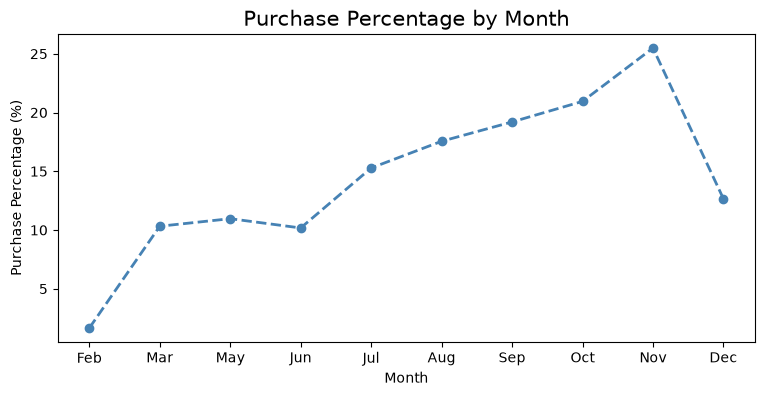

In [43]:
# Calculate purchase percentage for each month
monthly_purchase = df.groupby("month", observed=True)["revenue"].mean() * 100

# Arrange months in calendar order
monthly_purchase = monthly_purchase.reindex([
    "Feb", "Mar", "May", "Jun", "Jul",
    "Aug", "Sep", "Oct", "Nov", "Dec"
])

# Create a line chart
plt.figure(figsize=(9, 4))

plt.plot(
    monthly_purchase.index,
    monthly_purchase.values,
    marker="o",
    linestyle="--",
    linewidth=2,
    color="steelblue"
)

# Customize the chart
plt.title("Purchase Percentage by Month", fontsize=15)
plt.xlabel("Month")
plt.ylabel("Purchase Percentage (%)")

plt.show()

#### (v) Distribution of Total Pages Visited
- ***Visualization Type:*** Histogram (Matplotlib)
- ***Purpose:*** To examine the distribution of the total number of pages visited by customers during their browsing sessions.
- ***Insight:*** The histogram shows a right-skewed distribution, with most browsing sessions involving fewer than 100 page visits. The number of sessions decreases as page visits increase, while only a small number of sessions involve very high page counts.

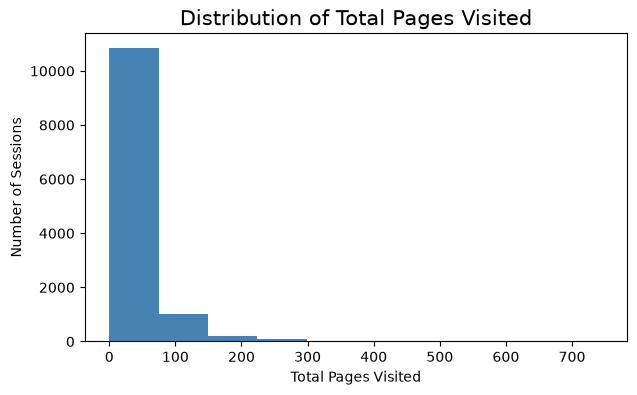

In [44]:
# Create a histogram
plt.figure(figsize=(7, 4))

plt.hist(
    df["total_pages_visited"],
    bins=10,
    color="steelblue"
)

# Customize the chart
plt.title("Distribution of Total Pages Visited", fontsize=15)
plt.xlabel("Total Pages Visited")
plt.ylabel("Number of Sessions")

plt.show()

#### (vi) Browsing Duration by Purchase Outcome

* **Visualization Type:** Box Plot (Seaborn)
* **Purpose:** To compare the distribution of browsing duration between sessions that resulted in a purchase and sessions that did not.
- **Insight:** Sessions resulting in a purchase show a higher median browsing duration than sessions without a purchase. Both groups contain high-duration outliers, with more extreme values in the No Purchase group. This suggests that longer browsing duration may be associated with purchasing behaviour, although browsing duration alone does not establish whether a purchase will occur.


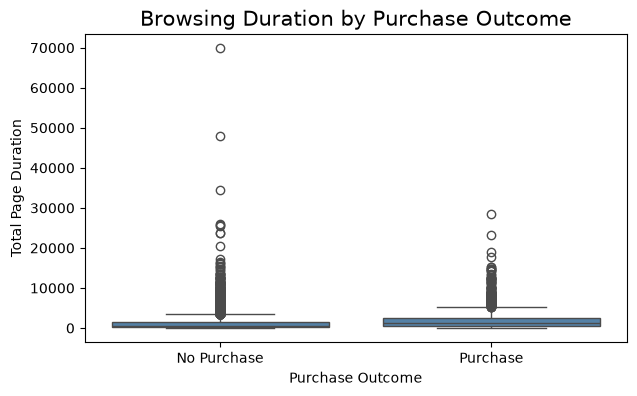

In [45]:
# Create a box plot
plt.figure(figsize=(7, 4))

sns.boxplot(
    data=df,
    x="revenue",
    y="total_page_duration",
    color="steelblue"
)

# Customize the chart
plt.title("Browsing Duration by Purchase Outcome", fontsize=15)
plt.xlabel("Purchase Outcome")
plt.ylabel("Total Page Duration")
plt.xticks([0, 1], ["No Purchase", "Purchase"])

plt.show()

#### (vii) Page Visits vs Browsing Duration
- ***Visualization Type:*** Scatter Plot (Matplotlib)
- ***Purpose:*** To examine the relationship between the total number of pages visited and the total duration spent on those pages
- ***Insight:*** The scatter plot shows a positive relationship between page visits and total page duration. Sessions with more page visits generally tend to have longer browsing durations, with a few extreme values.

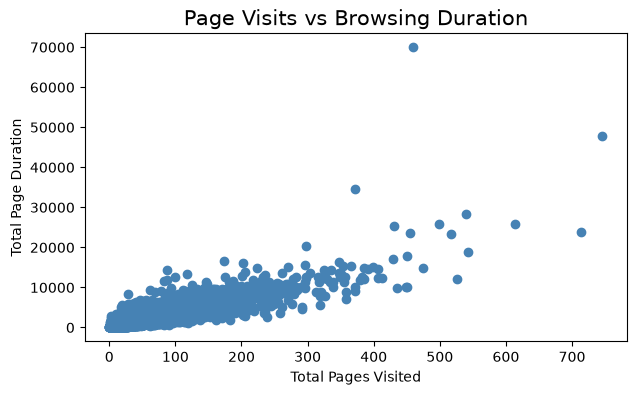

In [46]:
# Create a scatter plot
plt.figure(figsize=(7, 4))

plt.scatter(
    df["total_pages_visited"],
    df["total_page_duration"],
    color="steelblue"
)

# Customize the chart
plt.title("Page Visits vs Browsing Duration", fontsize=15)
plt.xlabel("Total Pages Visited")
plt.ylabel("Total Page Duration")

plt.show()

### (viii) Correlation Heatmap

* **Visualization Type:** Heatmap (Seaborn)
* **Purpose:** To visualise the correlations between numerical variables and identify positive and negative relationships.
* **Insight:** The heatmap shows strong positive correlations between bounce rates and exit rates, and between total page visits and total page duration. Page values have very weak correlations with the other variables.



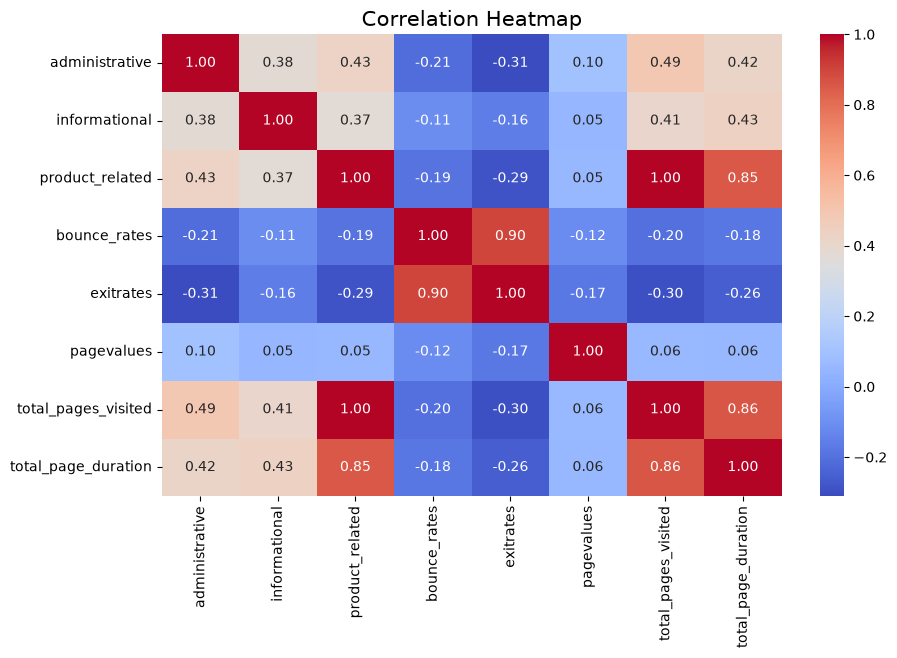

In [47]:
# Create a heatmap
plt.figure(figsize=(10, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

# Customize the chart
plt.title("Correlation Heatmap", fontsize=15)

plt.show()

### (ix) Interactive Purchase Percentage by Visitor Type

* **Visualization Type:** Interactive Bar Chart (Plotly)
* **Purpose:** To compare purchase percentages across visitor types using an interactive visualization.
* **Insight:** New visitors have the highest purchase percentage (24.93%), followed by Other visitors (19.75%) and Returning visitors (14.09%). Plotly allows users to explore these values interactively.


In [48]:
# Create an interactive bar chart
fig = px.bar(
    purchase_percentage,
    x=purchase_percentage.index,
    y=purchase_percentage.values,
    title="Interactive Purchase Percentage by Visitor Type",
    labels={
        "x": "Visitor Type",
        "y": "Purchase Percentage (%)"
    },
    color=purchase_percentage.index
)

fig.show(renderer="browser")

### (x) Purchase Behaviour by Weekend

* **Visualization Type:** Grouped Bar Chart (Seaborn)
* **Purpose:** To compare purchasing and non-purchasing sessions on weekdays and weekends.
* **Insight:** Weekdays have more sessions and purchases overall than weekends.

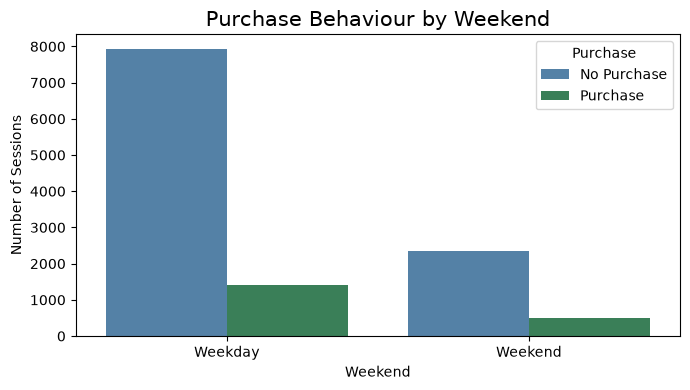

In [49]:
# Create a grouped bar chart
plt.figure(figsize=(7, 4))

sns.countplot(
    data=df,
    x="weekend",
    hue="revenue",
    palette={True: "seagreen", False: "steelblue"}
)

# Customize the chart
plt.title("Purchase Behaviour by Weekend", fontsize=15)
plt.xlabel("Weekend")
plt.ylabel("Number of Sessions")
plt.xticks([0, 1], ["Weekday", "Weekend"])
plt.legend(title="Purchase", labels=["No Purchase", "Purchase"])

plt.tight_layout()
plt.show()

### (xi) Purchase vs No Purchase

* **Visualization Type:** Pie Chart (Matplotlib)
* **Purpose:** To show the proportion of browsing sessions that resulted in a purchase compared with sessions that did not.
* **Insight:** The pie chart shows that 84.4% of browsing sessions did not result in a purchase, while only 15.6% resulted in a purchase. This indicates that most visitors leave the website without buying anything.

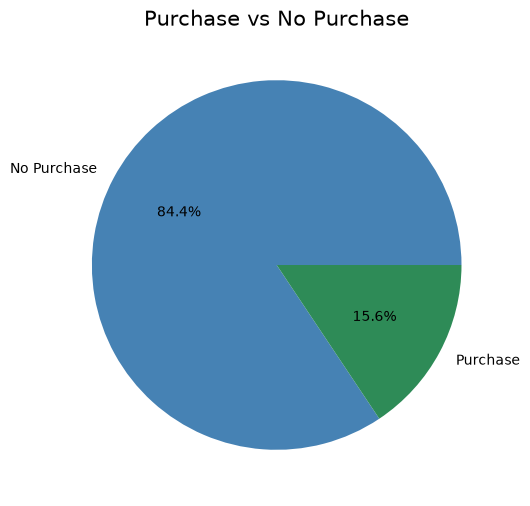

In [50]:
# Create a pie chart
purchase_counts = df["revenue"].value_counts()

plt.figure(figsize=(6, 6))
plt.pie(
    purchase_counts,
    labels=["No Purchase", "Purchase"],
    autopct="%1.1f%%",
    colors=["steelblue", "seagreen"]
)
# Customize the chart
plt.title("Purchase vs No Purchase", fontsize=15)
plt.show()


#### (xii) Browsing Duration by Purchase Outcome
* ***Visualization Type:*** Violin Plot (Seaborn)
* ***Purpose:*** To compare the distribution of total browsing duration between sessions that resulted in a purchase and sessions that did not.
* **Insight:** The violin plot shows that browsing durations are concentrated at lower values for both purchase outcomes. Sessions without a purchase have a longer upper tail, indicating that some of these sessions have exceptionally high browsing durations.

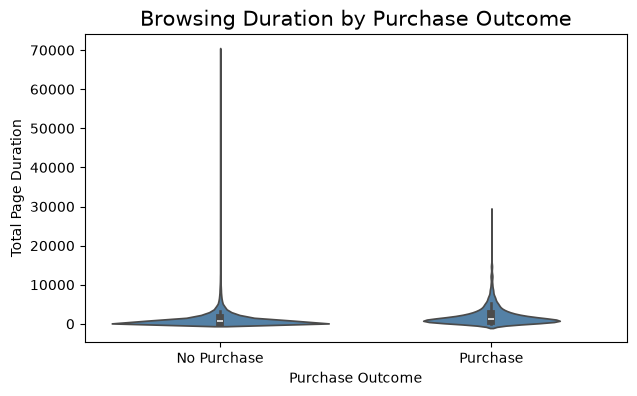

In [51]:
# Create a violin plot
plt.figure(figsize=(7, 4))

sns.violinplot(
    data=df,
    x="revenue",
    y="total_page_duration",
    color="steelblue"
)
# Customize the chart
plt.title("Browsing Duration by Purchase Outcome", fontsize=15)
plt.xlabel("Purchase Outcome")
plt.ylabel("Total Page Duration")
plt.xticks([0, 1], ["No Purchase", "Purchase"])
plt.show()


### (xiii) Browsing Duration by Purchase Outcome

* **Visualization Type:** Swarm Plot (Seaborn)
* **Purpose:** To compare individual browsing-duration observations for sessions with and without a purchase.
* **Insight:** Most sessions in the sample have shorter browsing durations. However, some sessions have much longer durations, both with and without a purchase.


c:\Users\aleet\AppData\Local\Programs\Python\Python313\Lib\site-packages\seaborn\categorical.py:3399: UserWarning: 7.2% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


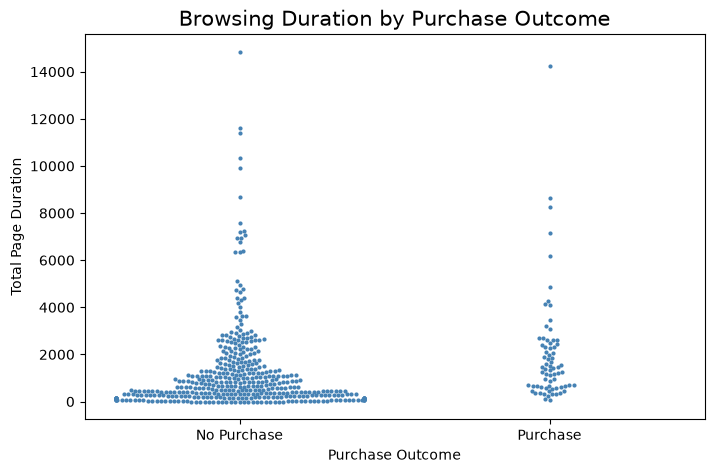

In [52]:
# Create a swarm plot
sample_df = df.sample(n=500, random_state=42)
plt.figure(figsize=(8, 5))

sns.swarmplot(
    data=sample_df,
    x="revenue",
    y="total_page_duration",
    color="steelblue",
    size=3
)

plt.title("Browsing Duration by Purchase Outcome", fontsize=15)
plt.xlabel("Purchase Outcome")
plt.ylabel("Total Page Duration")
plt.xticks([0, 1], ["No Purchase", "Purchase"])
plt.show()

<div style="
    border-left: 6px solid #2ecc71;
    background-color: #f4fff8;
    padding: 12px 16px;
    margin: 10px 0;
    font-size: 15px;
    color: #2c3e50;
">
<strong>✔ Visualizations Completed:</strong>
Visualizations were successfully created to explore customer browsing behaviour, purchase patterns, visitor types, monthly trends, browsing duration, and correlations between numerical variables.
</div>

<h2 style="
    text-align:center;
    background-color:#eef3ff;
    padding:10px 15px;
    border-radius:5px;
    color:#2c7be5;
    font-size:30px;
">
    Insight Generation and Report
</h2>


### Objective of the Analysis

The objective of this project was to analyze e-commerce browsing session data to understand customer behaviour and identify patterns associated with purchase intention. Through data preprocessing, exploratory data analysis (EDA), and data visualization, the study examined how visitor type, monthly trends, browsing activity, page visits, and browsing duration relate to purchase outcomes. The analysis aims to identify meaningful patterns that can help businesses better understand customer behaviour and explore opportunities to improve purchase conversion.


### Data Preparation Summary

The original dataset contained 12,330 browsing sessions and 18 columns describing customer behaviour and website activity. Data preprocessing was performed to improve data quality and prepare the dataset for analysis. Duplicate records were identified and removed, leaving 12,205 unique sessions. The dataset was checked for missing values and data types, and no missing values were found. Additional features, including total pages visited, browsing activity categories, and total page duration, were created to support further analysis. The month values were also standardized to three-letter abbreviations to improve consistency during grouping and visualization.


### Exploratory Data Analysis Overview

Exploratory data analysis revealed that most browsing sessions did not result in a purchase, with purchasing sessions accounting for approximately 15.63% of the cleaned dataset. Purchase behaviour varied across visitor types, months, weekends, and levels of browsing activity. New visitors showed a higher purchase percentage than returning visitors, while sessions with higher browsing activity had a greater purchase percentage than sessions with lower activity. The analysis also identified relationships between page visits and browsing duration, as well as a strong positive correlation between bounce rates and exit rates. These findings provided a foundation for further visual analysis of customer browsing behaviour and purchase outcomes.


### Key Analytical Insights from Visual Exploration


#### (i) Overall Purchase Behaviour

The analysis revealed that only 15.63% of browsing sessions resulted in a purchase, while 84.37% ended without a purchase. This indicates that most visitors browsed the website without completing a transaction. The difference highlights an opportunity for businesses to investigate potential barriers to purchase and explore strategies to improve conversion rates.


#### (ii) Purchase Behaviour by Visitor Type

The analysis showed that new visitors had the highest purchase percentage at 24.93%, followed by the "Other" visitor category at 19.75% and returning visitors at 14.09%. Although returning visitors accounted for the largest number of sessions and purchases, new visitors had a higher purchase rate. This suggests that visitor type may be associated with purchase behaviour and could be considered when developing customer engagement strategies.


#### (iii) Monthly Purchase Trends

November had the highest purchase percentage (25.49%), while February had the lowest (1.66%). The purchase percentage generally increased from June to November before dropping in December. This shows that purchase behaviour varied across months.


#### (iv) Browsing Activity and Purchase Intention

Sessions with high browsing activity had the highest purchase percentage (23.99%), while sessions with low activity had the lowest (5.81%). This suggests that visitors who explore more pages are more likely to make a purchase.


#### (v) Browsing Duration and Page Visits

The analysis showed that visitors who viewed more pages generally spent more time browsing. Sessions that resulted in a purchase also had a higher median browsing duration. However, longer browsing time did not always lead to a purchase.


#### (vi) Correlation Between Numerical Variables

The analysis showed a strong positive correlation between bounce rates and exit rates (0.90). Total pages visited and total page duration were also strongly correlated. However, page values had a weak correlation with total pages visited. These relationships help us understand how different browsing activities are connected.


### Conclusion

This project analyzed e-commerce browsing sessions to understand customer behaviour and purchase patterns. The analysis found that most sessions did not result in a purchase. New visitors and sessions with higher browsing activity had higher purchase percentages. Browsing duration and page visits were also related. These findings can help businesses better understand customer behaviour and identify opportunities to improve purchase conversion.


### Recommendations and Next Steps

Based on the analysis, the following recommendations may help improve purchase conversion:

* **Improve Conversion:** Identify why most browsing sessions do not result in purchases.
* **Engage New Visitors:** Explore ways to maintain the interest of new visitors and encourage purchases.
* **Improve Browsing Experience:** Make it easier for visitors to find relevant products and navigate the website.
* **Further Analysis:** Study customer behaviour across different months and visitor types to identify additional purchase patterns.


<div style="
    border-left: 6px solid #27ae60;
    background-color: #f3fcf7;
    padding: 16px 18px;
    margin-top: 20px;
    font-size: 15px;
    color: #2c3e50;
    border-radius: 4px;
">
<strong>✔ Project Completed Successfully</strong><br><br>
This project successfully completed data preprocessing, exploratory data analysis, analytical visualizations, insight generation, and reporting. The findings provide a clear understanding of e-commerce customer browsing behaviour and purchase patterns, helping identify opportunities to improve purchase conversion.
</div>